<a href="https://colab.research.google.com/github/cotri77/proyecto_abandono_escolar/blob/main/EduFuture_abandono_escolar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎓 EduFuture · Predicción del abandono escolar

**Objetivo:** crear un modelo que estime la probabilidad de que un estudiante **abandone sus estudios en los próximos 12 meses**, para ofrecerle apoyo a tiempo.

**Cómo está organizado**
1. Librerías y datos
2. Revisión de los datos
3. Exploración: ¿qué señales hay?
4. Variables que usa el modelo
5. Entrenamiento (regresión logística)
6. ¿Acierta? Evaluación
7. ¿Qué pesa más? Interpretación
8. Conclusiones y recomendaciones

> ⚠️ Los datos son **sintéticos** (2.400 estudiantes simulados). No son personas reales.

## 1. Librerías y datos

- `pandas` y `numpy`: trabajar con tablas y números.
- `matplotlib`: hacer gráficos.
- `scikit-learn`: preparar los datos, entrenar el modelo y medir sus resultados.

In [1]:
# --- CELDA 1: librerías ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# scikit-learn: preparar datos y crear el modelo
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# scikit-learn: medir los resultados
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Colores de los gráficos: azul = continúa · naranja = abandona
AZUL, NARANJA = "#4C72B0", "#DD8452"

Subimos el Excel. Al ejecutar la celda aparece el botón **"Elegir archivos"**: selecciona `edufuture_dataset_abandono_escolar_sintetico.xlsx` en tu ordenador.

In [2]:
# --- CELDA 2: subir y leer el Excel ---
from google.colab import files
subido = files.upload()           # aparece el botón "Elegir archivos"
ruta = list(subido.keys())[0]     # nombre con el que se ha guardado el archivo

df = pd.read_excel(ruta, sheet_name="01_Datos")   # los datos están en la hoja 01_Datos
df.head()

,id_estudiante,curso_academico,fecha_corte,comunidad_autonoma,entorno_municipio,titularidad_centro,etapa,curso_nivel,edad_anios,sexo_declarado,...,utilidad_percibida_estudios_1_5,pertenencia_centro_1_5,relacion_docentes_1_5,acoso_ultimos_30_dias,bienestar_autopercibido_1_5,apoyo_familiar_estudios_1_5,intencion_continuar_estudios_1_5,contacto_tutoria_hasta_corte,abandono_en_12_meses,particion_sugerida
0,EF0001,2025-2026,2025-10-15,Castilla y León,Rural,Concertado,4º ESO,4º ESO,17,Mujer,...,1,1,2,Varias veces al mes,3,2,3,1,0,entrenamiento
1,EF0002,2025-2026,2025-10-15,Extremadura,Urbano,Privado,Bachillerato,1º Bachillerato,16,Mujer,...,3,3,3,Varias veces al mes,3,2,2,1,0,entrenamiento
2,EF0003,2025-2026,2025-10-15,País Vasco,Urbano,Público,4º ESO,4º ESO,15,Hombre,...,4,4,3,Nunca,2,3,4,1,0,prueba
3,EF0004,2025-2026,2025-10-15,Andalucía,Urbano,Público,CFGM,1º CFGM,17,Mujer,...,4,3,3,Una vez,4,1,4,0,0,validacion
4,EF0005,2025-2026,2025-10-15,Región de Murcia,Urbano,Público,Bachillerato,2º Bachillerato,18,Mujer,...,2,2,2,Varias veces al mes,2,2,2,0,0,entrenamiento


## 2. Revisión de los datos

Antes de usar los datos, comprobamos que están **completos y que tienen sentido**.

In [3]:
# --- CELDA 3: revisión rápida ---
print("Filas y columnas:", df.shape)
print("Valores nulos (huecos):", df.isna().sum().sum())
print("Filas duplicadas:", df.drop(columns="id_estudiante").duplicated().sum())
print("Asistencia: de", df["asistencia_ultimos_30_dias_pct"].min(), "a", df["asistencia_ultimos_30_dias_pct"].max(), "(esperado: 45 a 100)")
print("Nota media: de", df["nota_media_trimestre_anterior_0_10"].min(), "a", df["nota_media_trimestre_anterior_0_10"].max(), "(esperado: 2,5 a 10)")
print("Valores de abandono:", sorted(df["abandono_en_12_meses"].unique().tolist()), "(0 = continúa, 1 = abandona)")

Filas y columnas: (2400, 36)
Valores nulos (huecos): 0
Filas duplicadas: 0
Asistencia: de 45.3 a 100.0 (esperado: 45 a 100)
Nota media: de 3.0 a 10.0 (esperado: 2,5 a 10)
Valores de abandono: [0, 1] (0 = continúa, 1 = abandona)


**Conclusión:** no hay huecos ni filas repetidas, y los valores están dentro de los rangos esperados. **No hace falta rellenar ni borrar nada.**

### Valores extremos (outliers)
Un valor es *extremo* si se aleja mucho del resto (regla del rango intercuartílico).

In [4]:
# --- CELDA 4: valores extremos ---
columnas = ["horas_trabajo_remunerado_semana", "horas_cuidados_familiares_semana",
            "horas_estudio_semana", "retrasos_ultimos_30_dias"]
filas = []
for col in columnas:
    q1, q3 = df[col].quantile([0.25, 0.75])
    rango = q3 - q1
    extremos = ((df[col] < q1 - 1.5 * rango) | (df[col] > q3 + 1.5 * rango)).sum()
    filas.append({"variable": col, "máximo": df[col].max(), "valores extremos": extremos,
                  "% del total": round(extremos / len(df) * 100, 1)})
pd.DataFrame(filas)

,variable,máximo,valores extremos,% del total
0,horas_trabajo_remunerado_semana,13,5,0.2
1,horas_cuidados_familiares_semana,11,14,0.6
2,horas_estudio_semana,25,2,0.1
3,retrasos_ultimos_30_dias,10,70,2.9


**Decisión: los mantenemos.** Son pocos y son valores posibles (por ejemplo, alguien que trabaja 13 horas a la semana). Además, suelen ser los estudiantes con **más riesgo**: borrarlos haría que el modelo ignorase a quienes más ayuda necesitan.

## 3. Exploración: ¿qué señales hay?

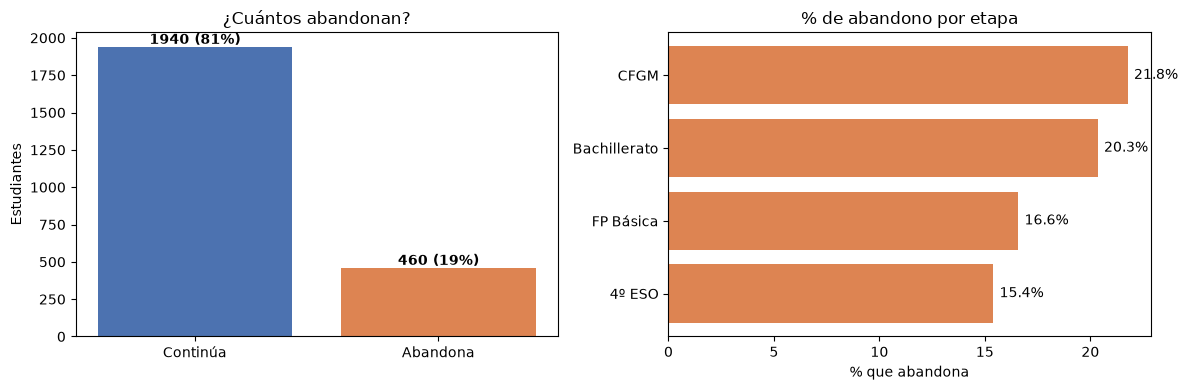

In [5]:
# --- CELDA 5: abandono total y por etapa ---
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

# Izquierda: cuántos continúan y cuántos abandonan
conteo = df["abandono_en_12_meses"].value_counts().sort_index()
ejes[0].bar(["Continúa", "Abandona"], conteo.values, color=[AZUL, NARANJA])
for i, n in enumerate(conteo.values):
    ejes[0].text(i, n + 20, f"{n} ({n / len(df):.0%})", ha="center", fontweight="bold")
ejes[0].set_title("¿Cuántos abandonan?")
ejes[0].set_ylabel("Estudiantes")

# Derecha: % de abandono en cada etapa
por_etapa = (df.groupby("etapa")["abandono_en_12_meses"].mean() * 100).sort_values()
ejes[1].barh(por_etapa.index, por_etapa.values, color=NARANJA)
for i, v in enumerate(por_etapa.values):
    ejes[1].text(v + 0.3, i, f"{v:.1f}%", va="center")
ejes[1].set_title("% de abandono por etapa")
ejes[1].set_xlabel("% que abandona")
plt.tight_layout()
plt.show()

**Conclusión:** abandona el **19,2 %** (casi 1 de cada 5). Hay muchos más estudiantes que continúan que estudiantes que abandonan: se llama **desbalance de clases**. Por eso el *accuracy* (porcentaje de aciertos) engaña: un modelo que dijera siempre «continúa» acertaría el 81 % sin detectar a nadie. **Nuestra métrica principal será el recall**: detectar a los que sí abandonan.

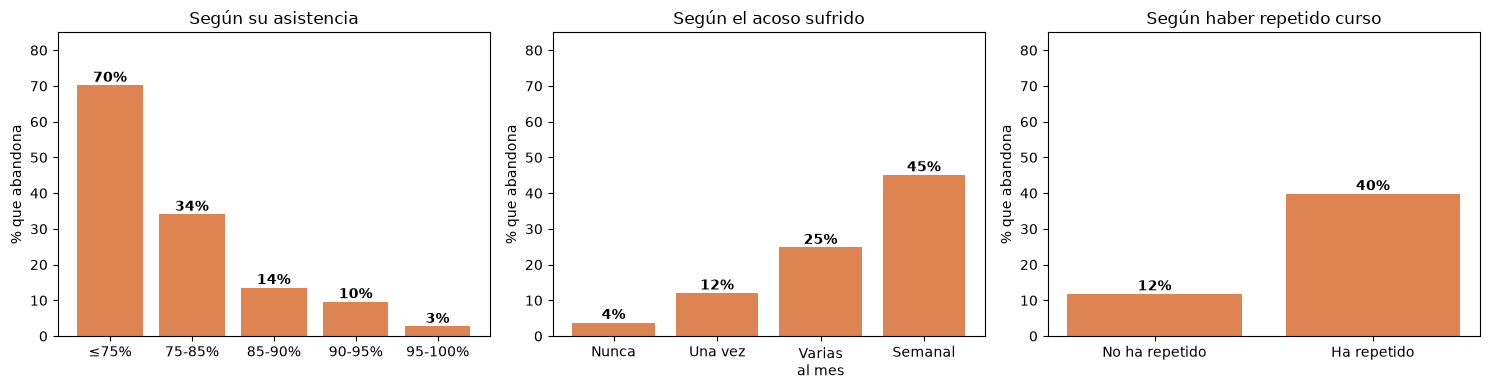

In [6]:
# --- CELDA 6: tres señales importantes ---
OBJETIVO = "abandono_en_12_meses"
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))

# 1) Asistencia por tramos
tramos = pd.cut(df["asistencia_ultimos_30_dias_pct"], [0, 75, 85, 90, 95, 100],
                labels=["≤75%", "75-85%", "85-90%", "90-95%", "95-100%"])
tasa = df.groupby(tramos, observed=True)[OBJETIVO].mean() * 100
ejes[0].bar(tasa.index.astype(str), tasa.values, color=NARANJA)
ejes[0].set_title("Según su asistencia")

# 2) Acoso
orden = ["Nunca", "Una vez", "Varias veces al mes", "Una vez por semana o más"]
tasa = df.groupby("acoso_ultimos_30_dias")[OBJETIVO].mean().reindex(orden) * 100
ejes[1].bar(["Nunca", "Una vez", "Varias\nal mes", "Semanal"], tasa.values, color=NARANJA)
ejes[1].set_title("Según el acoso sufrido")

# 3) Haber repetido curso
tasa = df.groupby("ha_repetido_curso")[OBJETIVO].mean() * 100
ejes[2].bar(["No ha repetido", "Ha repetido"], tasa.values, color=NARANJA)
ejes[2].set_title("Según haber repetido curso")

for ax in ejes:
    ax.set_ylabel("% que abandona")
    for barra in ax.patches:
        ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 1,
                f"{barra.get_height():.0f}%", ha="center", fontweight="bold")
    ax.set_ylim(0, 85)
plt.tight_layout()
plt.show()

**Conclusión:** el abandono se dispara cuando hay **poca asistencia**, **acoso** o **repetición de curso**. Son señales fáciles de detectar en un centro y **se puede actuar sobre ellas**.

## 4. Variables que usa el modelo

| Grupo | Variables | ¿Entran? |
|---|---|---|
| Rendimiento y asistencia | asistencia, retrasos, suspensos, nota media, horas de estudio, repetir curso | ✅ Sí |
| Contexto y carga | dificultad económica, trabajo, cuidados, internet, espacio de estudio, edad | ✅ Sí |
| Vínculo y bienestar | satisfacción, utilidad, pertenencia, relación con docentes, apoyo familiar, intención de continuar, **acoso** | ✅ Sí |
| Curso | curso (4º ESO, 1º Bach., 2º CFGM…) | ✅ Sí |
| Identificadores y fechas | id, curso académico, fecha de corte | ❌ No aportan información |
| Contacto de tutoría | si hubo tutoría antes del corte | ❌ Es una ayuda que ya se dio y confundiría el resultado |
| Variables sensibles | sexo, lugar de nacimiento, necesidad de apoyo, titularidad, comunidad | ❌ No deben decidir quién recibe ayuda |

In [7]:
# --- CELDA 7: variables del modelo ---
# El acoso viene en texto: lo convertimos en un número del 0 al 3 (tiene un orden natural)
df["acoso_0_3"] = df["acoso_ultimos_30_dias"].map(
    {"Nunca": 0, "Una vez": 1, "Varias veces al mes": 2, "Una vez por semana o más": 3})

VARIABLES_NUMERICAS = [
    "asistencia_ultimos_30_dias_pct", "retrasos_ultimos_30_dias", "materias_suspensas_trimestre_anterior",
    "nota_media_trimestre_anterior_0_10", "ha_repetido_curso", "horas_estudio_semana", "edad_anios",
    "dificultad_economica_hogar_1_5", "internet_estable_hogar", "espacio_adecuado_estudio",
    "horas_trabajo_remunerado_semana", "horas_cuidados_familiares_semana",
    "satisfaccion_programa_1_5", "utilidad_percibida_estudios_1_5", "pertenencia_centro_1_5",
    "relacion_docentes_1_5", "apoyo_familiar_estudios_1_5", "intencion_continuar_estudios_1_5",
    "acoso_0_3",
]
VARIABLES_CATEGORICAS = ["curso_nivel"]    # el curso ya incluye la etapa

PREDICTORAS = VARIABLES_NUMERICAS + VARIABLES_CATEGORICAS
print("Variables que usa el modelo:", len(PREDICTORAS))

Variables que usa el modelo: 20


### División de los datos

El Excel ya trae una columna que reparte a los estudiantes en tres grupos:
- **Entrenamiento (70 %):** el modelo aprende con ellos.
- **Prueba (15 %):** es el *examen final*. El modelo nunca los ve mientras aprende.
- **Validación (15 %):** reservado. En esta versión sencilla no lo usamos.

In [8]:
# --- CELDA 8: entrenamiento y prueba ---
entrenamiento = df[df["particion_sugerida"] == "entrenamiento"]
prueba = df[df["particion_sugerida"] == "prueba"]

X_train, y_train = entrenamiento[PREDICTORAS], entrenamiento[OBJETIVO]
X_test, y_test = prueba[PREDICTORAS], prueba[OBJETIVO]

print("Entrenamiento:", len(X_train), "estudiantes · abandona el", f"{y_train.mean():.1%}")
print("Prueba:       ", len(X_test), "estudiantes · abandona el", f"{y_test.mean():.1%}")

Entrenamiento: 1680 estudiantes · abandona el 19.2%
Prueba:        360 estudiantes · abandona el 19.2%


## 5. Entrenamiento: regresión logística

**¿Por qué este modelo?**
- Calcula una **probabilidad** de abandono para cada estudiante.
- Es **interpretable**: nos dice qué variables suben o bajan el riesgo. Para una ONG que debe justificar a quién ayuda, eso es fundamental.

**Tres decisiones:**
1. **`StandardScaler`**: pone todas las variables numéricas en la misma escala, para poder comparar su peso.
2. **`OneHotEncoder`**: convierte el curso (texto) en columnas de 0 y 1.
3. **`class_weight="balanced"`**: como pocos estudiantes abandonan, le pedimos al modelo que **les preste más atención**.

Todo va dentro de un **`Pipeline`**, una cadena de pasos que se aplica siempre igual: el escalado se calcula solo con los datos de entrenamiento, así evitamos hacer trampas con los de prueba.

In [9]:
# --- CELDA 9: pipeline y entrenamiento ---
preparacion = ColumnTransformer([
    ("numericas", StandardScaler(), VARIABLES_NUMERICAS),
    ("categoricas", OneHotEncoder(drop="first", handle_unknown="ignore"), VARIABLES_CATEGORICAS),
])

modelo = Pipeline([
    ("preparacion", preparacion),
    ("regresion", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

modelo.fit(X_train, y_train)      # el modelo aprende con los estudiantes de entrenamiento
print("Modelo entrenado ✅")

Modelo entrenado ✅


## 6. ¿Acierta? Evaluación

Ahora hacemos el **examen final** con los estudiantes de prueba, que el modelo no había visto nunca. El modelo marca «en riesgo» cuando la probabilidad de abandono supera el 50 %.

In [10]:
# --- CELDA 10: métricas ---
y_pred = modelo.predict(X_test)                    # 0 = continúa · 1 = abandona
y_prob = modelo.predict_proba(X_test)[:, 1]        # probabilidad de abandono

print(f"Recall:    {recall_score(y_test, y_pred):.1%}   -> de los que abandonan, % que detectamos")
print(f"Precision: {precision_score(y_test, y_pred):.1%}   -> de las alertas, % que son abandonos reales")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.1%}   -> aciertos totales")
print(f"F1-score:  {f1_score(y_test, y_pred):.3f}   -> nota que combina recall y precision")
print(f"AUC-ROC:   {roc_auc_score(y_test, y_prob):.3f}   -> capacidad de ordenar por riesgo (1 = perfecto, 0,5 = azar)")

Recall:    79.7%   -> de los que abandonan, % que detectamos
Precision: 55.0%   -> de las alertas, % que son abandonos reales
Accuracy:  83.6%   -> aciertos totales
F1-score:  0.651   -> nota que combina recall y precision
AUC-ROC:   0.910   -> capacidad de ordenar por riesgo (1 = perfecto, 0,5 = azar)


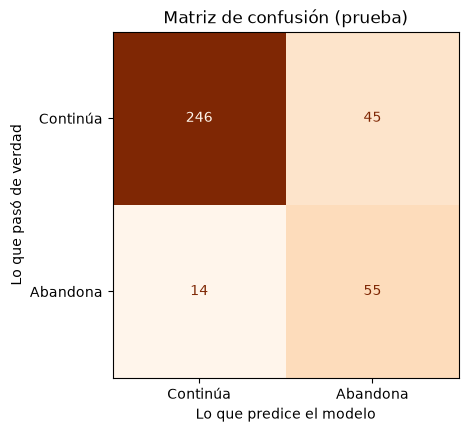

✅ Abandonos detectados:               55
❌ Abandonos NO detectados:            14   (error más grave)
⚠️ Falsas alarmas (continúan):         45   (cuestan una tutoría de más)
✅ Continúan y no se marcan:           246


In [11]:
# --- CELDA 11: matriz de confusión ---
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Continúa", "Abandona"],
                                        cmap="Oranges", colorbar=False, ax=ax)
ax.set_xlabel("Lo que predice el modelo")
ax.set_ylabel("Lo que pasó de verdad")
ax.set_title("Matriz de confusión (prueba)")
ax.grid(False)
plt.show()

vn, fp, fn, vp = confusion_matrix(y_test, y_pred).ravel()
print(f"✅ Abandonos detectados:               {vp}")
print(f"❌ Abandonos NO detectados:            {fn}   (error más grave)")
print(f"⚠️ Falsas alarmas (continúan):         {fp}   (cuestan una tutoría de más)")
print(f"✅ Continúan y no se marcan:           {vn}")

**Cómo leer los resultados**
- **Recall:** de cada 10 estudiantes que abandonan, el modelo detecta unos 8. Es la métrica que más nos importa: lo peor es que alguien abandone sin que nadie lo vea.
- **Precision:** algo más de la mitad de las alertas son abandonos reales. El resto son falsas alarmas, pero una falsa alarma solo cuesta una conversación de tutoría.
- **Accuracy:** parece alta, pero ya vimos que engaña con clases desbalanceadas.
- **AUC-ROC (~0,91):** el modelo ordena muy bien a los estudiantes de menos a más riesgo.

## 7. ¿Qué pesa más? Interpretación

Cada variable tiene un **coeficiente**: su peso en el modelo.
- **Positivo** → sube el riesgo de abandono.
- **Negativo** → lo baja (protege).

Como las variables están en la misma escala, los coeficientes son comparables.

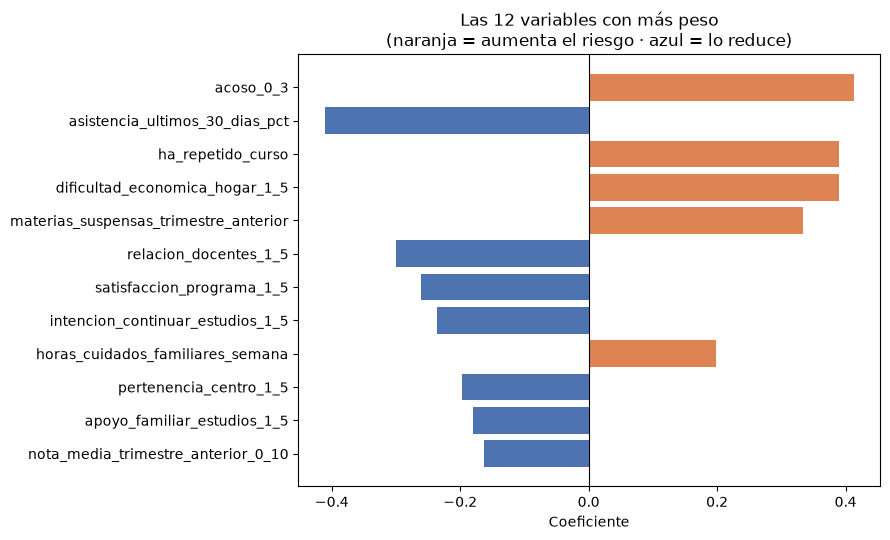

acoso_0_3                                0.41
asistencia_ultimos_30_dias_pct          -0.41
ha_repetido_curso                        0.39
dificultad_economica_hogar_1_5           0.39
materias_suspensas_trimestre_anterior    0.33
relacion_docentes_1_5                   -0.30
satisfaccion_programa_1_5               -0.26
intencion_continuar_estudios_1_5        -0.24
horas_cuidados_familiares_semana         0.20
pertenencia_centro_1_5                  -0.20
apoyo_familiar_estudios_1_5             -0.18
nota_media_trimestre_anterior_0_10      -0.16
dtype: float64

In [12]:
# --- CELDA 12: coeficientes ---
nombres = [n.split("__")[1] for n in modelo.named_steps["preparacion"].get_feature_names_out()]
coeficientes = pd.Series(modelo.named_steps["regresion"].coef_[0], index=nombres)
coeficientes = coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index)

# No mostramos los cursos: sus coeficientes dependen del curso de referencia (1º Bachillerato)
coeficientes = coeficientes[~coeficientes.index.str.startswith("curso_nivel")]

top = coeficientes.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index, top.values, color=[NARANJA if c > 0 else AZUL for c in top.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Las 12 variables con más peso\n(naranja = aumenta el riesgo · azul = lo reduce)")
ax.set_xlabel("Coeficiente")
plt.tight_layout()
plt.show()

coeficientes.head(12).round(2)

## 8. Conclusiones y recomendaciones

### Resultados (conjunto de prueba, 360 estudiantes que el modelo no había visto)

| Métrica | Valor | Qué significa |
|---|---|---|
| **Recall** | **79,7 %** | Detecta **55 de los 69** abandonos (casi 8 de cada 10) |
| Precision | 55,0 % | 55 de las 100 alertas son abandonos reales |
| Accuracy | 83,6 % | Aciertos totales (solo orientativo) |
| F1-score | 0,651 | Equilibrio entre recall y precision |
| AUC-ROC | 0,910 | Ordena muy bien a los estudiantes por riesgo |

- El modelo marca a **100 de 360** estudiantes (28 %). Es una carga asumible para un equipo de tutoría.
- Se le escapan **14** abandonos y da **45** falsas alarmas. Preferimos una falsa alarma (una conversación de más) a un abandono sin detectar.

### ¿Qué factores explican el abandono?

| Aumentan el riesgo ↑ | Protegen ↓ |
|---|---|
| **Sufrir acoso** | **Asistencia alta** (el factor que más protege) |
| **Haber repetido curso** | Buena relación con el profesorado |
| **Dificultad económica** en el hogar | Satisfacción con el programa |
| **Materias suspensas** | Intención de seguir estudiando |
| Horas de cuidados familiares | |

La mayoría son **señales que un centro puede detectar y sobre las que puede actuar**.

> No mostramos los coeficientes de *curso*: comparan cada curso con 1º de Bachillerato y algunos grupos son pequeños (2º de FP Básica tiene solo 86 estudiantes). Además, los coeficientes indican **asociación, no causalidad**.

### Recomendaciones

| Señal de riesgo | Acción | Quién |
|---|---|---|
| Asistencia baja o muchos retrasos | Tutoría individual y contacto temprano con la familia | Tutor / jefatura |
| Suspensos, nota baja o repetición de curso | Plan de recuperación y refuerzo | Orientación |
| Acoso | Protocolo de convivencia y apoyo psicoeducativo | Convivencia / orientación |
| Dificultad económica | Becas, ayudas de comedor y transporte, servicios sociales | Trabajo social |
| Muchas horas de trabajo o cuidados | Flexibilizar horarios y entregas | Dirección y tutoría |
| Baja satisfacción o intención de continuar | Orientación vocacional | Orientación |

### Limitaciones y siguientes pasos
- Los datos son **sintéticos**: con datos reales habría que reentrenar y volver a validar el modelo.
- Hemos usado **un solo modelo** y el umbral estándar del 50 %.
- **No hemos auditado la equidad**: el modelo no usa variables sensibles, pero habría que medir si detecta igual de bien a todos los grupos (sexo, origen…).
- **La alerta no decide**: cada aviso lo revisa una persona antes de actuar, y se ofrece apoyo, nunca una sanción.